# Continuous Winner's Curse: Randomized Winner Selection with Conditionally Valid Confidence Intervals

This notebook joins the two earlier notebooks (`simulatation_winners_curse.ipynb` and
`real_data_winners_curse.ipynb`) and adds the new method on top of each.

| Part | What it does | Source |
|---|---|---|
| **I** | Synthetic alpha field over the entry z-threshold $s \in D=[0.5,4]$, naive **argmax** winner, winner's-curse bias | original simulation notebook |
| **II** | **New.** Winner drawn by the **exponential mechanism** (continuous Gibbs kernel) and a **conditionally valid CI** for the true alpha $\theta(s_J)$ of the selected threshold; coverage/regret/length checks | new |
| **III** | Real data: SPY 20-day mean-reversion strategy, observed alpha field, block bootstrap, bias correction | original real-data notebook |
| **IV** | **New.** The same randomized selection + conditional CI on SPY, with a bootstrap-world calibration check | new |

**The estimand.** Whatever selection rule we use, the reported number is about *the threshold we
actually chose*: $\theta(s_J)$, the true (population) annualized alpha of the strategy run at
the selected entry threshold $s_J$. This is the "selected winner value" row of the targets table
in the working notes, not the global best $\max_s\theta(s)$.

**The guarantee.** For every possible selected location $j$,
$$\Pr\big\{\theta(s_J) \in C_J \,\big|\, J=j\big\} \ge 1-\alpha .$$
That is, *given that the randomized search handed us threshold $s_j$*, the interval covers that
threshold's true alpha with probability $1-\alpha$. This is the probability guarantee that matters
if the chosen threshold is then traded in real time.

In [1]:
# %pip install -q numpy scipy pandas matplotlib yfinance
import csv
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from scipy.stats import norm

---
# Part I: Simulation, argmax winner (original notebook)

## Continuous Winner's Curse — Initial Simulation

A synthetic 1D field standing in for a backtested alpha surface over a continuous
entry z-score threshold, D = [0.5, 4.0].

We know the *true* performance surface θ(s) because we set it ourselves — something
we never get to see in real data. This lets us check that the naive "winning"
backtest result is biased upward relative to the truth, which is the whole
phenomenon this project is trying to correct for.

**What this notebook does:**
1. Builds a dense grid approximation of the continuous domain D
2. Defines a true, modest performance surface θ(s)
3. Adds spatially correlated Gaussian noise (standing in for shared trade history
   between nearby thresholds)
4. Repeats the "sweep, pick the winner" process many times and measures the gap
   between the naive reported result and the true value at that same point
5. Exports the resulting data for further analysis (e.g. testing a correction method)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import csv

## 1. The grid

A true continuum can't be stored, so we approximate D = [0.5, 4.0] with a dense
grid of M points. Rerun with different M later to confirm results are stable as
the grid gets denser (the "good lattice" approximation discussed with Soham).

In [3]:
M = 1000
s_grid = np.linspace(0.5, 4.0, M)

## 2. The true performance surface θ(s)

A single smooth bump centered at `s0`, representing a modest real effect
somewhere in the parameter space. In real data we never observe this directly —
only the noisy X(s). Here, since it's a simulation, we set it ourselves so we
have a ground truth to check against.

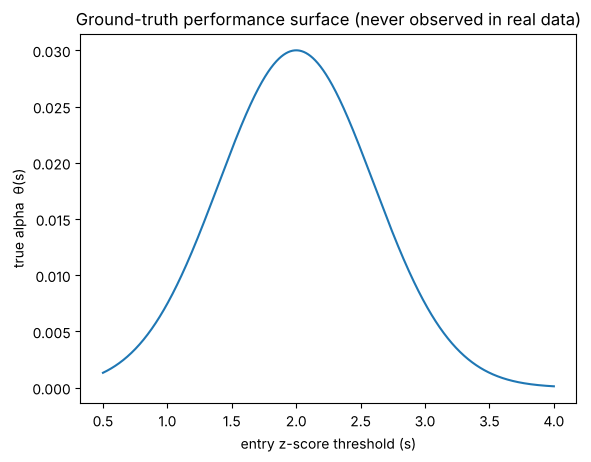

In [4]:
s0 = 2.0                    # location of the true optimal threshold
true_peak_height = 0.03     # true alpha at the optimum (3% annualized)
width = 0.6                 # how quickly true performance decays away from s0

theta = true_peak_height * np.exp(-0.5 * ((s_grid - s0) / width) ** 2)

plt.plot(s_grid, theta)
plt.xlabel("entry z-score threshold (s)")
plt.ylabel("true alpha  θ(s)")
plt.title("Ground-truth performance surface (never observed in real data)")
plt.show()

## 3. Correlated Gaussian noise ε(s)

Nearby z-values share overlapping trade history, so the noise isn't independent
across the grid — it's a smooth, spatially correlated process. We model this with
a squared-exponential (RBF) covariance kernel: `corr_length` controls how far
apart two thresholds need to be before their noise becomes nearly independent.

In a real backtest, this correlation length would be *estimated* from the data
(e.g. via a stationary/block bootstrap on the overlapping trade windows) rather
than set by hand as we do here.

In [5]:
rng = np.random.default_rng(42)

noise_sd = 0.05        # standard deviation of the noise at each point
corr_length = 0.15     # distance at which noise becomes nearly uncorrelated

def rbf_kernel(x, length_scale, sd):
    diffs = x[:, None] - x[None, :]
    return sd**2 * np.exp(-0.5 * (diffs / length_scale) ** 2)

K = rbf_kernel(s_grid, corr_length, noise_sd)
K += 1e-10 * np.eye(M)   # jitter for numerical stability (Cholesky)
L = np.linalg.cholesky(K)

def sample_field():
    """One draw of the noisy field X(s) = theta(s) + eps(s)."""
    z = rng.standard_normal(M)
    return theta + L @ z

## 4. One example realization

Before running the full simulation, look at a single simulated backtest sweep:
the true curve, the noisy observed curve, and which point the naive search
would report as the "winner."

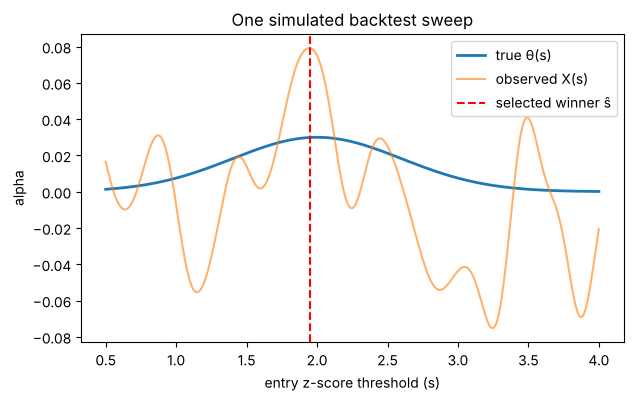

Selected ŝ = 1.947
Naive reported alpha at ŝ:  0.0792
TRUE alpha at that same ŝ:  0.0299


In [6]:
X_example = sample_field()
i_hat_example = np.argmax(X_example)

plt.figure(figsize=(7, 4))
plt.plot(s_grid, theta, label="true θ(s)", lw=2)
plt.plot(s_grid, X_example, label="observed X(s)", alpha=0.6)
plt.axvline(s_grid[i_hat_example], color="red", ls="--", label="selected winner ŝ")
plt.xlabel("entry z-score threshold (s)")
plt.ylabel("alpha")
plt.title("One simulated backtest sweep")
plt.legend()
plt.show()

print(f"Selected ŝ = {s_grid[i_hat_example]:.3f}")
print(f"Naive reported alpha at ŝ:  {X_example[i_hat_example]:.4f}")
print(f"TRUE alpha at that same ŝ:  {theta[i_hat_example]:.4f}")

## 5. Repeated simulation — measuring the winner's-curse bias

Repeat the "sweep and pick the winner" process many times. Each repeat is an
independent simulated world. For each one, record:
- the naive reported performance at the winning threshold
- the TRUE performance at that same threshold (only knowable because this is a
  simulation)

The gap between these two, averaged across simulations, is the winner's-curse
bias we're trying to quantify and eventually correct for.

In [7]:
n_sims = 2000
naive_reported = np.empty(n_sims)
true_at_winner = np.empty(n_sims)
winner_location = np.empty(n_sims)

for i in range(n_sims):
    X = sample_field()
    i_hat = np.argmax(X)
    naive_reported[i] = X[i_hat]
    true_at_winner[i] = theta[i_hat]
    winner_location[i] = s_grid[i_hat]

bias = naive_reported.mean() - true_at_winner.mean()

print(f"Average naive reported performance at the winner:  {naive_reported.mean():.4f}")
print(f"Average TRUE performance at that same location:    {true_at_winner.mean():.4f}")
print(f"Estimated winner's-curse bias:                     {bias:.4f}")
print(f"Average selected s_hat across simulations:          {winner_location.mean():.3f}  (true optimum s0 = {s0})")

Average naive reported performance at the winner:  0.1111
Average TRUE performance at that same location:    0.0163
Estimated winner's-curse bias:                     0.0948
Average selected s_hat across simulations:          2.188  (true optimum s0 = 2.0)


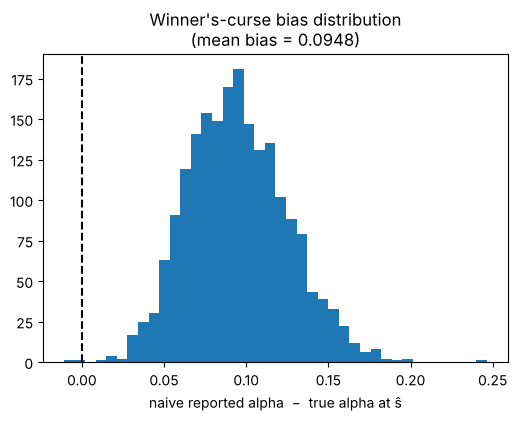

In [8]:
plt.figure(figsize=(6, 4))
plt.hist(naive_reported - true_at_winner, bins=40)
plt.axvline(0, color="black", ls="--")
plt.xlabel("naive reported alpha  −  true alpha at ŝ")
plt.title(f"Winner's-curse bias distribution\n(mean bias = {bias:.4f})")
plt.show()

## 6. Export the data

Two files, for use outside this notebook (e.g. testing a correction method, or
sharing with Soham):

- **`simulation_results.csv`** — one row per simulated sweep: the selected ŝ, the
  naive reported value, and the true value at that location
- **`example_field.csv`** — the single example field from Section 4: every grid
  point, its true θ(s), the observed X(s), and which point was the winner

In [9]:
with open("simulation_results.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["sim_id", "s_hat", "naive_reported_X", "true_theta_at_s_hat"])
    for i in range(n_sims):
        writer.writerow([i, f"{winner_location[i]:.6f}", f"{naive_reported[i]:.6f}", f"{true_at_winner[i]:.6f}"])

with open("example_field.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["s", "theta_true", "X_observed", "is_winner"])
    for j in range(M):
        writer.writerow([f"{s_grid[j]:.6f}", f"{theta[j]:.6f}", f"{X_example[j]:.6f}", int(j == i_hat_example)])

print("Saved simulation_results.csv and example_field.csv")

Saved simulation_results.csv and example_field.csv


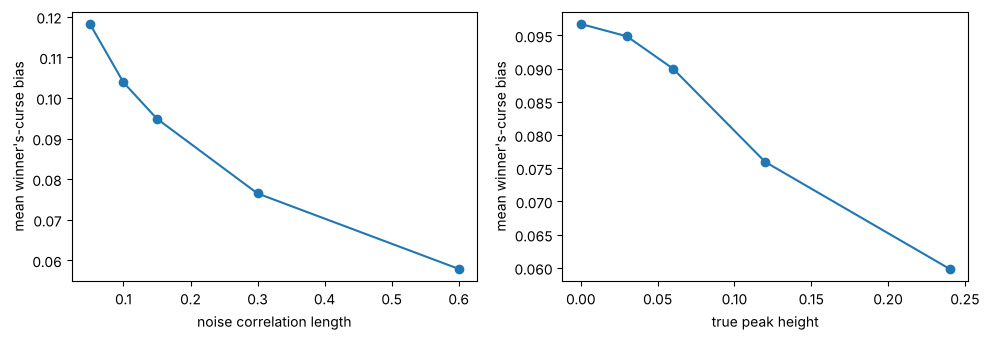

corr_length=0.05: bias=0.1182
corr_length=0.1: bias=0.1038
corr_length=0.15: bias=0.0949
corr_length=0.3: bias=0.0765
corr_length=0.6: bias=0.0579
peak=0.0: bias=0.0967
peak=0.03: bias=0.0949
peak=0.06: bias=0.0900
peak=0.12: bias=0.0759
peak=0.24: bias=0.0598


In [10]:
def run_sims(corr_length=0.15, M=1000, n_sims=500, noise_sd=0.05, peak=0.03, seed=0):
    rng_ = np.random.default_rng(seed)
    s = np.linspace(0.5, 4.0, M)
    th = peak * np.exp(-0.5 * ((s - s0) / width) ** 2)
    K_ = rbf_kernel(s, corr_length, noise_sd) + 1e-8 * noise_sd**2 * np.eye(M)
    L_ = np.linalg.cholesky(K_)
    X_ = th[:, None] + L_ @ rng_.standard_normal((M, n_sims))
    i = X_.argmax(axis=0)
    return (X_[i, np.arange(n_sims)] - th[i]).mean()

corr_lengths = [0.05, 0.1, 0.15, 0.3, 0.6]
bias_by_corr = [run_sims(corr_length=c) for c in corr_lengths]
peaks = [0.0, 0.03, 0.06, 0.12, 0.24]
bias_by_peak = [run_sims(peak=p) for p in peaks]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(corr_lengths, bias_by_corr, "o-")
ax[0].set_xlabel("noise correlation length"); ax[0].set_ylabel("mean winner's-curse bias")
ax[1].plot(peaks, bias_by_peak, "o-")
ax[1].set_xlabel("true peak height"); ax[1].set_ylabel("mean winner's-curse bias")
plt.tight_layout(); plt.show()

for c, b in zip(corr_lengths, bias_by_corr): print(f"corr_length={c}: bias={b:.4f}")
for p, b in zip(peaks, bias_by_peak):        print(f"peak={p}: bias={b:.4f}")

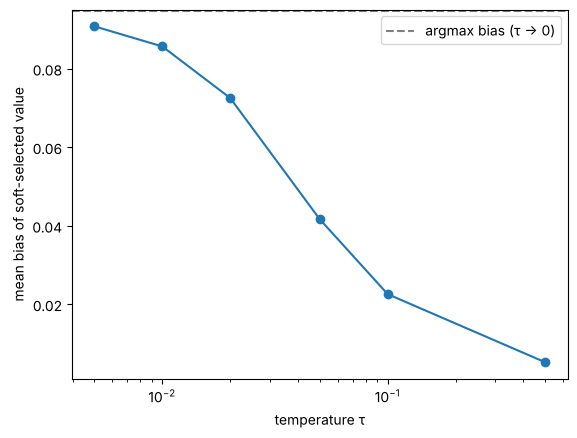

tau=0.005: bias=0.0908
tau=0.01: bias=0.0857
tau=0.02: bias=0.0726
tau=0.05: bias=0.0416
tau=0.1: bias=0.0226
tau=0.5: bias=0.0052


In [11]:
def softmax_bias(tau, n_sims=500, seed=0):
    rng_ = np.random.default_rng(seed)
    out = []
    for _ in range(n_sims):
        X_ = theta + L @ rng_.standard_normal(M)
        w = np.exp((X_ - X_.max()) / tau); w /= w.sum()
        out.append(w @ X_ - w @ theta)       # soft-selected value minus its true value
    return np.mean(out)

taus = np.array([0.005, 0.01, 0.02, 0.05, 0.1, 0.5])
bias_by_tau = [softmax_bias(t) for t in taus]

plt.semilogx(taus, bias_by_tau, "o-")
plt.axhline(bias, color="gray", ls="--", label="argmax bias (τ → 0)")
plt.xlabel("temperature τ"); plt.ylabel("mean bias of soft-selected value"); plt.legend(); plt.show()

for t, b in zip(taus, bias_by_tau): print(f"tau={t}: bias={b:.4f}")

---
# Part II: Exponential-mechanism winner and a conditionally valid CI (simulation)

## II.1 The selection rule: a Gibbs kernel on the continuous domain

Instead of reporting $\hat s=\arg\max_s X(s)$, we **sample** the winner from the exponential
mechanism. On the continuous domain $D$ with a declared base measure $\omega$ (here: uniform /
Lebesgue on $D$), it is the Gibbs kernel from the working notes,
$$
\Pr(S\in \mathrm ds \mid X) \;=\;
\frac{\exp\{\epsilon\,[u(X;s)-\bar u_X]/\hat\sigma_X\}\;\omega(s)\,\mathrm ds}
     {\int_D \exp\{\epsilon\,[u(X;\xi)-\bar u_X]/\hat\sigma_X\}\;\omega(\xi)\,\mathrm d\xi},
$$
with

* score $u(X;s)=X(s)$: the observed (annualized) alpha at threshold $s$. This is the signed analogue
  of the matched-filter score in the notes. We want *high* alpha, not high $|$alpha$|$.
* **adaptive scale** $\hat\sigma_X$: the spread of the scores under $\omega$, $\bar u_X=\int u\,\mathrm d\omega$ and
  $\hat\sigma_X^2=\int (u-\bar u_X)^2\mathrm d\omega$. This is the $k=1$ version of the `scale="adaptive"` rule in
  `src/Randomized_PSI.py`. So $\epsilon$ is unit-free: the temperature is $\tau=\hat\sigma_X/\epsilon$,
  and $\epsilon\to\infty$ recovers the argmax.

**Discretization.** A continuum can't be stored, so the integrals are evaluated by quadrature on the
dense grid of Part I. With an equispaced grid and uniform $\omega$ the quadrature weights are equal,
i.e. counting measure on the grid, and the discrete law converges to the continuous kernel as
$M\to\infty$ (checked in II.6). The base measure is part of the selector: a different $\omega$
(e.g. putting more mass on economically plausible thresholds) gives a different, equally valid,
procedure.

## II.2 Conditional inference for $\theta(s_J)$

Model: $X\sim N(\theta,\Sigma)$ on the grid. For the selected index $j$ write
$$
b_j=\Sigma_{\cdot j}/\Sigma_{jj},\qquad R_j = X - b_j X_j ,
$$
so $R_j$ is independent of $X_j$ and $X = R_j + b_j X_j$. Conditional on $\{J=j,\;R_j=r\}$ the
selected value $X_j$ has density (the notes' eq. for $f^\star$, with our score)
$$
f^\star_{\theta_j}(t\mid j,r)\;\propto\;
\varphi\!\Big(\frac{t-\theta_j}{\sigma_j}\Big)\;
\pi_\epsilon\big(j \mid r+b_j t\big),
\qquad
\pi_\epsilon(j\mid x)=\frac{\exp\{\epsilon(x_j-\bar x)/\hat\sigma_x\}\,\omega_j}{\sum_k\exp\{\epsilon(x_k-\bar x)/\hat\sigma_x\}\,\omega_k}.
$$
The selection probability $\pi_\epsilon$ is **known** (we ran the sampler ourselves), so this is a
one-parameter family in $\theta_j$ with monotone likelihood ratio. The pivot
$F_{\theta_j}(X_j)\sim \mathrm{Unif}(0,1)$ *exactly*, given $J=j$, and inverting it gives
$$
C_J=\{\theta:\ \alpha/2 \le F_\theta(X_J) \le 1-\alpha/2\},\qquad
\hat\theta^{\rm MUE}_J = \{\theta: F_\theta(X_J)=1/2\}\ \text{(median-unbiased estimate)} .
$$
Only the column $\Sigma_{\cdot j}$ is needed (no matrix inversion), and the conditional density is
evaluated on a 1-D grid in $t$ and inverted on a grid in $\theta$.

Why randomize at all? With a hard argmax the selection event has (essentially) no wiggle room near a
tie, and conditioning on it leaves almost no information, so the intervals blow up. A positive
temperature keeps the selection law smooth; $\epsilon$ trades **regret** (how far $\theta(s_J)$ is
from $\max_s\theta(s)$) against **interval length**.

In [12]:
def em_logits(U, eps, w=None, floor=1e-12):
    # Gibbs logits  eps * (U - Ubar) / sd(U) + log w   (column-wise if U is 2-D).
    # Ubar and sd are taken w.r.t. the base measure w (normalized quadrature weights on the grid).
    U = np.asarray(U, float)
    M_ = U.shape[0]
    w = np.full(M_, 1.0 / M_) if w is None else np.asarray(w, float) / np.sum(w)
    W = w.reshape((M_,) + (1,) * (U.ndim - 1))
    ubar = (W * U).sum(0)
    sd = np.sqrt((W * (U - ubar) ** 2).sum(0) + floor ** 2)
    return eps * (U - ubar) / sd + np.log(W)


def em_select(X, eps, rng, w=None):
    # Draw J ~ softmax(em_logits(X)) exactly via the Gumbel-max trick. X: (M,) or (M, n_fields).
    lg = em_logits(X, eps, w)
    return np.argmax(lg + rng.gumbel(size=lg.shape), axis=0)


def em_probs(X, eps, w=None):
    lg = em_logits(X, eps, w)
    return np.exp(lg - logsumexp(lg, axis=0))


def conditional_inference(X, Sigma_j, j, eps, alpha=0.05, w=None, theta0=None,
                          nt=1401, t_span=14.0, nth=401, th_range=(-10.0, 6.0)):
    # Selective inference for theta_j given J = j under X ~ N(theta, Sigma), J ~ exponential mechanism.
    #   X       : observed field (M,)
    #   Sigma_j : Cov(X, X_j), the j-th column of Sigma (M,)
    # Returns the (1-alpha) conditional CI, the median-unbiased estimate, and (optionally) the pivot at theta0.
    X = np.asarray(X, float)
    s2 = Sigma_j[j]
    sj = np.sqrt(s2)
    b = Sigma_j / s2
    r = X - b * X[j]                     # residual, independent of X_j
    x = X[j]
    t = x + sj * np.linspace(-t_span, t_span, nt)
    mid = (nt - 1) // 2                  # t[mid] == x exactly
    lg = em_logits(r[:, None] + b[:, None] * t[None, :], eps, w)
    logsel = lg[j] - logsumexp(lg, axis=0)          # log pi_eps(j | r + b t), adaptive scale recomputed per t

    def F_at(th):
        th = np.atleast_1d(np.asarray(th, float))
        lf = -0.5 * ((t[None] - th[:, None]) / sj) ** 2 + logsel[None]
        f = np.exp(lf - lf.max(1, keepdims=True))
        c = np.concatenate([np.zeros((len(th), 1)), np.cumsum(0.5 * (f[:, 1:] + f[:, :-1]), 1)], 1)
        return c[:, mid] / c[:, -1]                 # F_theta(x), decreasing in theta

    th = x + sj * np.linspace(*th_range, nth)
    Fx = F_at(th)
    inv = lambda p: float(np.interp(p, Fx[::-1], th[::-1]))
    out = dict(j=int(j), x=x, se=sj, lower=inv(1 - alpha / 2), upper=inv(alpha / 2), mue=inv(0.5),
               hit_edge=bool(Fx[0] < 1 - alpha / 2 or Fx[-1] > alpha / 2), logsel=logsel, t=t)
    if theta0 is not None:
        out["pivot"] = float(F_at(theta0)[0])
    return out

## II.3 One realization: where the mechanism samples, and the conditional density

Same simulated world as Part I ($\theta$, $\Sigma$ = RBF kernel, $M=1000$). We keep handles on the
simulation objects because Part III reuses some variable names.

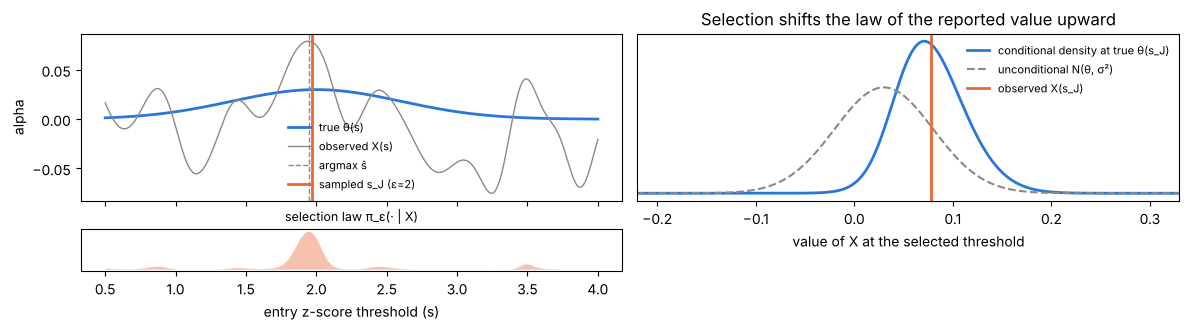

argmax ŝ = 1.947  vs  sampled s_J = 1.971
naive reported X(s_J)        = 0.0782
true θ(s_J)                  = 0.0300
median-unbiased estimate     = 0.0349
naive 95% Wald CI            = [-0.0198, 0.1762]
conditional 95% CI (ours)    = [-0.1100, 0.1580]


In [13]:
sim_s, sim_theta, sim_K, sim_L, sim_M = s_grid, theta, K, L, M
sim_sd = np.sqrt(np.diag(sim_K))
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a85"

EPS = 2.0          # privacy-style "inverse temperature"; tau = (spread of X) / EPS
ALPHA = 0.05
rng_em = np.random.default_rng(2026)

X_ex = X_example                                  # the Part I example field
p_ex = em_probs(X_ex, EPS)
J_ex = int(em_select(X_ex, EPS, rng_em))
res_ex = conditional_inference(X_ex, sim_K[:, J_ex], J_ex, EPS, alpha=ALPHA, theta0=sim_theta[J_ex])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(sim_s, sim_theta, c=C_BLUE, lw=2, label="true θ(s)")
ax[0].plot(sim_s, X_ex, c=C_GRAY, lw=1, label="observed X(s)")
ax[0].axvline(sim_s[np.argmax(X_ex)], c=C_GRAY, ls="--", lw=1, label="argmax ŝ")
ax[0].axvline(sim_s[J_ex], c=C_ORANGE, lw=2, label=f"sampled s_J (ε={EPS:g})")
ax0b = ax[0].inset_axes([0.0, -0.42, 1.0, 0.25])
ax0b.fill_between(sim_s, p_ex, color=C_ORANGE, alpha=0.4, lw=0)
ax0b.set_yticks([]); ax0b.set_xlabel("entry z-score threshold (s)"); ax0b.set_title("selection law π_ε(· | X)", fontsize=9)
ax[0].set_ylabel("alpha"); ax[0].legend(fontsize=8, frameon=False); ax[0].set_xticklabels([])

# conditional density of X_J at the true theta, vs the naive N(theta, sigma^2)
t, ls_ = res_ex["t"], res_ex["logsel"]
for th0, col, lab in [(sim_theta[J_ex], C_BLUE, "conditional density at true θ(s_J)")]:
    lf = -0.5 * ((t - th0) / res_ex["se"]) ** 2 + ls_
    f = np.exp(lf - lf.max()); f /= np.trapezoid(f, t)
    ax[1].plot(t, f, c=col, lw=2, label=lab)
ax[1].plot(t, norm.pdf(t, sim_theta[J_ex], res_ex["se"]), c=C_GRAY, ls="--", label="unconditional N(θ, σ²)")
ax[1].axvline(res_ex["x"], c=C_ORANGE, lw=2, label="observed X(s_J)")
ax[1].set_xlim(sim_theta[J_ex] - 5 * res_ex["se"], sim_theta[J_ex] + 6 * res_ex["se"])
ax[1].set_xlabel("value of X at the selected threshold"); ax[1].set_yticks([]); ax[1].legend(fontsize=8, frameon=False)
ax[1].set_title("Selection shifts the law of the reported value upward")
plt.tight_layout(); plt.show()

print(f"argmax ŝ = {sim_s[np.argmax(X_ex)]:.3f}  vs  sampled s_J = {sim_s[J_ex]:.3f}")
print(f"naive reported X(s_J)        = {res_ex['x']:.4f}")
print(f"true θ(s_J)                  = {sim_theta[J_ex]:.4f}")
print(f"median-unbiased estimate     = {res_ex['mue']:.4f}")
print(f"naive 95% Wald CI            = [{res_ex['x'] - 1.96 * res_ex['se']:.4f}, {res_ex['x'] + 1.96 * res_ex['se']:.4f}]")
print(f"conditional 95% CI (ours)    = [{res_ex['lower']:.4f}, {res_ex['upper']:.4f}]")

## II.4 Repeated simulation: bias, coverage, length, regret

Each replicate is a new simulated world drawn from the same $\theta$ and $\Sigma$. Every method sees the
**same data**. To make data splitting comparable, we draw two independent halves
$X^{(1)},X^{(2)}\sim N(\theta,2\Sigma)$ and set $X=(X^{(1)}+X^{(2)})/2\sim N(\theta,\Sigma)$:

| Method | Winner | Interval |
|---|---|---|
| Naive (argmax) | $\arg\max X$ | $X_{\hat s}\pm 1.96\sigma$ |
| Naive (EM) | $J\sim\pi_\epsilon(\cdot\mid X)$ | $X_J\pm 1.96\sigma$ |
| Data splitting | $\arg\max X^{(1)}$ | $X^{(2)}_{\hat s}\pm 1.96\sqrt2\sigma$ |
| **EM + conditional (ours)** | $J\sim\pi_\epsilon(\cdot\mid X)$ | $C_J$ from II.2 |

In [14]:
def run_methods(theta_, K_, L_, eps, n_rep, seed, alpha=0.05):
    rng_ = np.random.default_rng(seed)
    M_ = len(theta_)
    sd_ = np.sqrt(np.diag(K_))
    z = norm.ppf(1 - alpha / 2)
    rows = []
    for _ in range(n_rep):
        X1 = theta_ + np.sqrt(2) * (L_ @ rng_.standard_normal(M_))
        X2 = theta_ + np.sqrt(2) * (L_ @ rng_.standard_normal(M_))
        X_ = 0.5 * (X1 + X2)
        th_best = theta_.max()
        # naive argmax
        i = int(np.argmax(X_))
        rows.append(dict(method="Naive (argmax)", s=sim_s_of(M_)[i], est=X_[i], truth=theta_[i],
                         lo=X_[i] - z * sd_[i], hi=X_[i] + z * sd_[i], regret=th_best - theta_[i]))
        # data splitting
        i = int(np.argmax(X1))
        rows.append(dict(method="Data splitting", s=sim_s_of(M_)[i], est=X2[i], truth=theta_[i],
                         lo=X2[i] - z * np.sqrt(2) * sd_[i], hi=X2[i] + z * np.sqrt(2) * sd_[i], regret=th_best - theta_[i]))
        # exponential mechanism
        j = int(em_select(X_, eps, rng_))
        rows.append(dict(method="Naive (EM)", s=sim_s_of(M_)[j], est=X_[j], truth=theta_[j],
                         lo=X_[j] - z * sd_[j], hi=X_[j] + z * sd_[j], regret=th_best - theta_[j]))
        o = conditional_inference(X_, K_[:, j], j, eps, alpha=alpha, theta0=theta_[j])
        rows.append(dict(method="EM + conditional (ours)", s=sim_s_of(M_)[j], est=o["mue"], truth=theta_[j],
                         lo=o["lower"], hi=o["upper"], regret=th_best - theta_[j], pivot=o["pivot"], edge=o["hit_edge"]))
    df = pd.DataFrame(rows)
    df["covered"] = (df.lo <= df.truth) & (df.truth <= df.hi)
    df["length"] = df.hi - df.lo
    df["error"] = df.est - df.truth
    return df


def sim_s_of(M_):
    return np.linspace(0.5, 4.0, M_)


def summarize(df):
    g = df.groupby("method", sort=False)
    return pd.DataFrame({"coverage": g.covered.mean(), "mean_length": g.length.mean(),
                         "bias(est - θ(s_sel))": g.error.mean(), "mean_regret": g.regret.mean(),
                         "mean_selected_s": g.s.mean()})


N_REP = 1000
res_main = run_methods(sim_theta, sim_K, sim_L, EPS, N_REP, seed=11, alpha=ALPHA)
summary_main = summarize(res_main)
print(f"ε = {EPS},  {N_REP} replicates,  nominal coverage {1 - ALPHA:.0%}")
print(summary_main.round(4).to_string())
print(f"\n(MC s.e. of a 95% coverage estimate ≈ {np.sqrt(0.95 * 0.05 / N_REP):.3f};  "
      f"CI hit the θ-search edge in {res_main.edge.fillna(False).astype(bool).sum()} replicates)")

ε = 2.0,  1000 replicates,  nominal coverage 95%
                         coverage  mean_length  bias(est - θ(s_sel))  mean_regret  mean_selected_s
method                                                                                            
Naive (argmax)              0.566       0.1960                0.0943       0.0132           2.1277
Data splitting              0.946       0.2772               -0.0007       0.0155           2.1749
Naive (EM)                  0.784       0.1960                0.0678       0.0138           2.1641
EM + conditional (ours)     0.961       0.2379                0.0011       0.0138           2.1641

(MC s.e. of a 95% coverage estimate ≈ 0.007;  CI hit the θ-search edge in 0 replicates)


**Reading the table.** Both naive intervals are centred at a value biased upward by selection, so they
under-cover; the argmax is the worst. Data splitting is valid but throws away half the data for
inference *and* for selection. The conditional interval reaches nominal coverage while using all the
data for both, and its median-unbiased estimate removes most of the winner's-curse bias.

### Is the guarantee really *conditional*?

Coverage should hold for every selected location, not just on average. Below: the pivot
$F_{\theta(s_J)}(X_J)$ should be Uniform(0,1), and coverage should be flat across bins of the
selected threshold $s_J$.

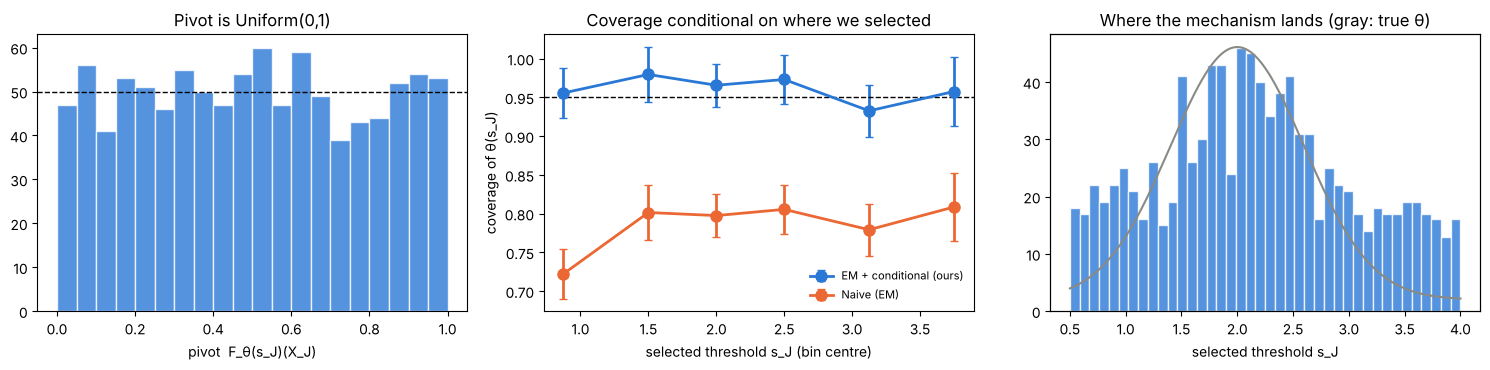

                 n  coverage  mean_length
s_bin                                    
(0.499, 1.25]  180     0.956        0.237
(1.25, 1.75]   146     0.979        0.241
(1.75, 2.25]   232     0.966        0.240
(2.25, 2.75]   185     0.973        0.239
(2.75, 3.5]    163     0.933        0.233
(3.5, 4.0]      94     0.957        0.236


In [15]:
ours = res_main[res_main.method == "EM + conditional (ours)"].copy()
naive_em = res_main[res_main.method == "Naive (EM)"].copy()
bins = np.array([0.5, 1.25, 1.75, 2.25, 2.75, 3.5, 4.0])
for d in (ours, naive_em):
    d["s_bin"] = pd.cut(d.s, bins, include_lowest=True)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(ours["pivot"], bins=20, range=(0, 1), color=C_BLUE, alpha=0.8, edgecolor="white")
ax[0].axhline(len(ours) / 20, c="k", ls="--", lw=1)
ax[0].set_xlabel("pivot  F_θ(s_J)(X_J)"); ax[0].set_title("Pivot is Uniform(0,1)")

for d, col, lab in [(ours, C_BLUE, "EM + conditional (ours)"), (naive_em, C_ORANGE, "Naive (EM)")]:
    cv = d.groupby("s_bin", observed=True).covered.agg(["mean", "size"])
    xm = [iv.mid for iv in cv.index]
    ax[1].errorbar(xm, cv["mean"], yerr=1.96 * np.sqrt(0.95 * 0.05 / cv["size"]), marker="o", ms=8, c=col, lw=2, capsize=3, label=lab)
ax[1].axhline(1 - ALPHA, c="k", ls="--", lw=1)
ax[1].set_xlabel("selected threshold s_J (bin centre)"); ax[1].set_ylabel("coverage of θ(s_J)")
ax[1].set_title("Coverage conditional on where we selected"); ax[1].legend(fontsize=8, frameon=False)

ax[2].hist(ours.s, bins=40, color=C_BLUE, alpha=0.8, edgecolor="white")
ax2 = ax[2].twinx(); ax2.plot(sim_s, sim_theta, c=C_GRAY, lw=1.5); ax2.set_yticks([])
ax[2].set_xlabel("selected threshold s_J"); ax[2].set_title("Where the mechanism lands (gray: true θ)")
plt.tight_layout(); plt.show()

print(ours.groupby("s_bin", observed=True).agg(n=("covered", "size"), coverage=("covered", "mean"),
                                               mean_length=("length", "mean")).round(3).to_string())

## II.5 The ε trade-off: regret vs. interval length

$\epsilon$ controls how greedy the selection is. Small $\epsilon$ means nearly uniform sampling: short
intervals, but we often deploy a poor threshold. Large $\epsilon$ approaches the argmax: lower regret
but longer conditional intervals. Coverage stays nominal throughout. We show the Part I world
(peak 0.03, SNR $\approx 0.6$) and a stronger-signal world (peak 0.12) where the search can actually find
the peak.

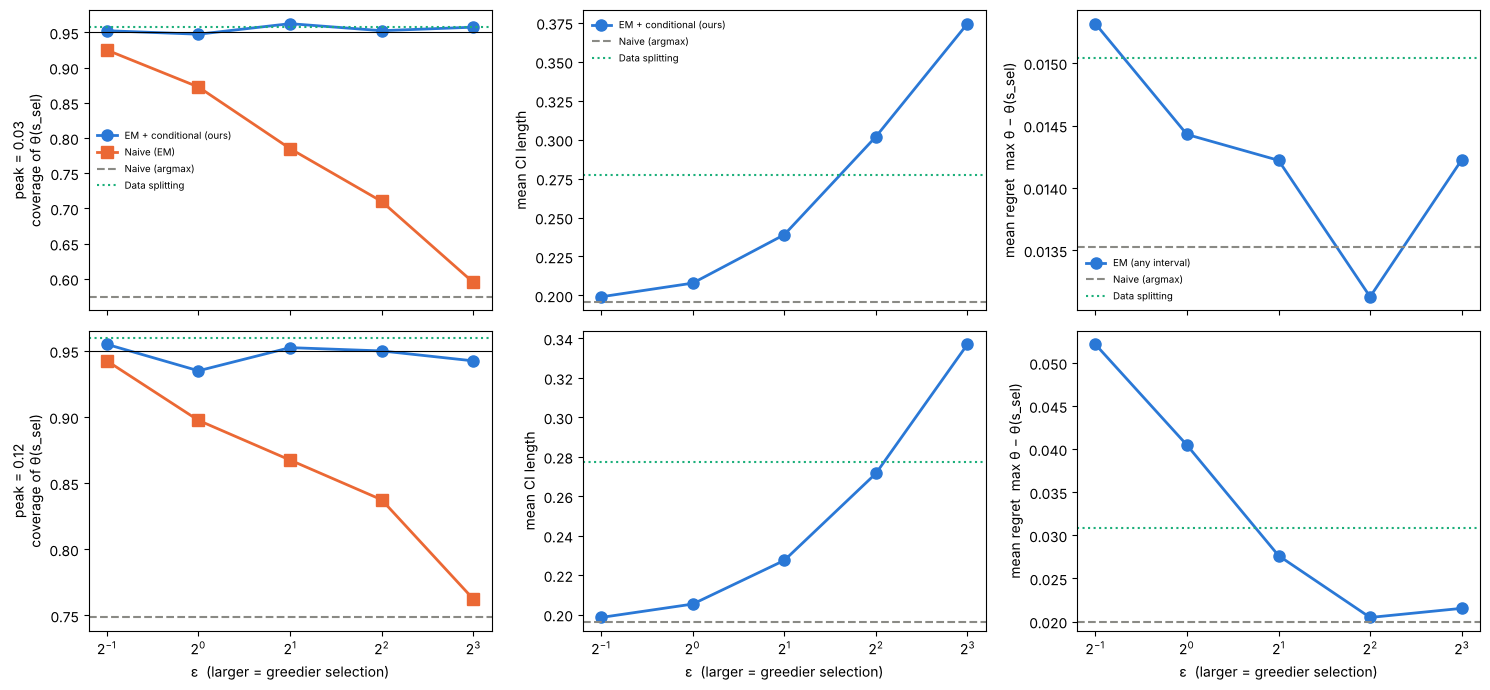

               coverage                                                      mean_length                                                      mean_regret                                                  
method   Data splitting EM + conditional (ours) Naive (EM) Naive (argmax) Data splitting EM + conditional (ours) Naive (EM) Naive (argmax) Data splitting EM + conditional (ours) Naive (EM) Naive (argmax)
peak eps                                                                                                                                                                                                   
0.03 0.5          0.952                   0.952      0.925          0.575          0.277                   0.199      0.196          0.196          0.015                   0.015      0.015          0.013
     1.0          0.955                   0.948      0.872          0.565          0.277                   0.208      0.196          0.196          0.016                   0.014      0

In [16]:
eps_list = [0.5, 1.0, 2.0, 4.0, 8.0]
N_SWEEP = 400
sweep = []
for peak_ in [0.03, 0.12]:
    th_ = peak_ * np.exp(-0.5 * ((sim_s - s0) / width) ** 2)
    for e in eps_list:
        d = run_methods(th_, sim_K, sim_L, e, N_SWEEP, seed=100 + int(10 * e), alpha=ALPHA)
        sm = summarize(d).reset_index(); sm["eps"] = e; sm["peak"] = peak_
        sweep.append(sm)
sweep = pd.concat(sweep, ignore_index=True)

fig, ax = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for r_, peak_ in enumerate([0.03, 0.12]):
    sw = sweep[sweep.peak == peak_]
    for m, col, mk in [("EM + conditional (ours)", C_BLUE, "o"), ("Naive (EM)", C_ORANGE, "s")]:
        q = sw[sw.method == m]
        ax[r_, 0].plot(q.eps, q.coverage, marker=mk, ms=8, c=col, lw=2, label=m)
        if m.startswith("EM"):
            ax[r_, 1].plot(q.eps, q.mean_length, marker=mk, ms=8, c=col, lw=2, label=m)
            ax[r_, 2].plot(q.eps, q.mean_regret, marker=mk, ms=8, c=col, lw=2, label="EM (any interval)")
    for m, col, ls in [("Naive (argmax)", C_GRAY, "--"), ("Data splitting", C_AQUA, ":")]:
        q = sw[sw.method == m]
        ax[r_, 0].axhline(q.coverage.mean(), c=col, ls=ls, lw=1.5, label=m)
        ax[r_, 1].axhline(q.mean_length.mean(), c=col, ls=ls, lw=1.5, label=m)
        ax[r_, 2].axhline(q.mean_regret.mean(), c=col, ls=ls, lw=1.5, label=m)
    ax[r_, 0].axhline(1 - ALPHA, c="k", lw=0.8)
    ax[r_, 0].set_ylabel(f"peak = {peak_}\ncoverage of θ(s_sel)")
    ax[r_, 1].set_ylabel("mean CI length"); ax[r_, 2].set_ylabel("mean regret  max θ − θ(s_sel)")
for a in ax[1]:
    a.set_xscale("log", base=2); a.set_xlabel("ε  (larger = greedier selection)")
ax[0, 0].legend(fontsize=7, frameon=False); ax[0, 1].legend(fontsize=7, frameon=False); ax[0, 2].legend(fontsize=7, frameon=False)
plt.tight_layout(); plt.show()

print(sweep.pivot_table(index=["peak", "eps"], columns="method", values=["coverage", "mean_length", "mean_regret"]).round(3).to_string())

## II.6 Continuity check: results don't depend on the grid

The method targets the continuous Gibbs kernel, and the grid is only quadrature. Refining the grid
(same $D$, same $\epsilon$, same kernel) should leave the selection law and the intervals essentially
unchanged. This is the "good lattice" check from Part I, applied to the new procedure.

In [17]:
grid_rows = []
for M_ in [250, 500, 1000, 2000]:
    s_ = np.linspace(0.5, 4.0, M_)
    th_ = true_peak_height * np.exp(-0.5 * ((s_ - s0) / width) ** 2)
    K_ = rbf_kernel(s_, corr_length, noise_sd) + 1e-8 * noise_sd ** 2 * np.eye(M_)
    L_ = np.linalg.cholesky(K_)
    d = run_methods(th_, K_, L_, EPS, 300, seed=7, alpha=ALPHA)
    d = d[d.method == "EM + conditional (ours)"]
    grid_rows.append(dict(M=M_, coverage=d.covered.mean(), mean_length=d.length.mean(),
                          mean_selected_s=d.s.mean(), sd_selected_s=d.s.std(), mean_regret=d.regret.mean()))
print(pd.DataFrame(grid_rows).round(4).to_string(index=False))

   M  coverage  mean_length  mean_selected_s  sd_selected_s  mean_regret
 250    0.9700       0.2396           2.0253         0.8433       0.0130
 500    0.9733       0.2394           2.2033         0.9119       0.0146
1000    0.9467       0.2359           2.1437         0.8985       0.0139
2000    0.9467       0.2401           2.2435         0.9397       0.0151


---
# Part III: Real data, SPY mean reversion (original notebook)

Unchanged except for a stray character at the top of the first cell. Note that this part reuses names such as `M`, `s_grid`, `X`, `bias`, `rng`; the simulation objects were saved as `sim_*` above.

Source: yfinance download
2514 trading days: 2016-01-04 to 2025-12-31
Buy-and-hold total return: 300.3%
Annualized return:         14.9%
Annualized vol:            18.0%
Days with |return| > 8% (expect March 2020):
Date
2020-03-12   -0.096
2020-03-13    0.085
2020-03-16   -0.109
2020-03-24    0.091
2025-04-09    0.105


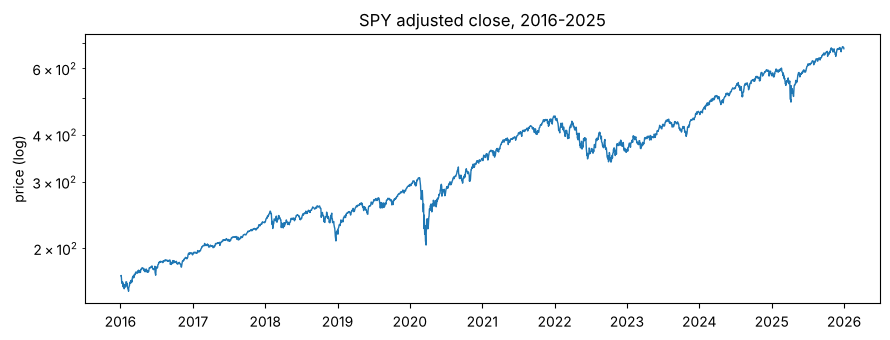

Saved spy_prices.csv (2514,)


In [18]:
# pip install numpy pandas matplotlib yfinance
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TICKER = "SPY"          # use "^GSPC" for the raw index
START  = "2016-01-01"
LAST   = "2025-12-31"   # last day we want (inclusive)
END    = "2026-01-01"   # yfinance 'end' is exclusive, so this includes 2025-12-31
OUT    = "spy_prices.csv"
RAW    = "spy_raw.csv"  # manual fallback: Yahoo Finance CSV with Date and Adj Close/Close

def load_prices():
    try:
        import yfinance as yf
        d = yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)
        if d is None or len(d) == 0:
            raise RuntimeError("empty download")
        if isinstance(d.columns, pd.MultiIndex):   # newer yfinance returns (field, ticker)
            d.columns = d.columns.get_level_values(0)
        s = d["Close"].copy()
        print("Source: yfinance download")
    except Exception as e:
        print(f"Download failed ({type(e).__name__}); trying local {RAW}")
        if not os.path.exists(RAW):
            raise FileNotFoundError(f"Put a Yahoo Finance CSV at {RAW}")
        d = pd.read_csv(RAW, parse_dates=["Date"], index_col="Date")
        col = "Adj Close" if "Adj Close" in d.columns else "Close"
        s = d[col].astype(float)
        print(f"Source: {RAW} (column {col})")
    s.index = pd.to_datetime(s.index).tz_localize(None)
    s = s.sort_index().loc[START:LAST]
    s.name = "close"
    return s

prices = load_prices()

# Sanity checks
assert prices.index.is_monotonic_increasing and prices.index.is_unique
assert prices.notna().all(), "NaNs in prices"
assert (prices > 0).all()
assert prices.index[0] <= pd.Timestamp("2016-01-08"), f"starts late: {prices.index[0]}"   # first trading day is 2016-01-04
assert prices.index[-1] >= pd.Timestamp("2025-12-24"), f"ends early: {prices.index[-1]}"
n = len(prices)
assert 2480 <= n <= 2540, f"unexpected number of trading days: {n}"   # ~252 * 10 years

rets = prices.pct_change().dropna()
print(f"{n} trading days: {prices.index[0].date()} to {prices.index[-1].date()}")
print(f"Buy-and-hold total return: {prices.iloc[-1]/prices.iloc[0]-1:.1%}")
print(f"Annualized return:         {(prices.iloc[-1]/prices.iloc[0])**(252/n)-1:.1%}")
print(f"Annualized vol:            {rets.std()*np.sqrt(252):.1%}")
print("Days with |return| > 8% (expect March 2020):")
print(rets[rets.abs() > 0.08].round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(prices.index, prices.values, lw=1)
ax.set_yscale("log"); ax.set_title(f"{TICKER} adjusted close, 2016-2025"); ax.set_ylabel("price (log)")
plt.tight_layout(); plt.show()

prices.to_frame().to_csv(OUT)
print("Saved", OUT, prices.shape)

Global winner: s_hat = 2.871, naive alpha = 1.91%, beta = 0.10, entries = 12

Top-5 local maxima (of smoothed curve):
     s  naive_alpha   beta  n_entries
2.9198       0.0191 0.0972         12
3.7545       0.0014 0.0020          1
2.0291      -0.0232 0.5120         40
1.9379      -0.0241 0.5215         42
2.1974      -0.0249 0.4960         35

Fraction of grid with zero trades: 6.0%


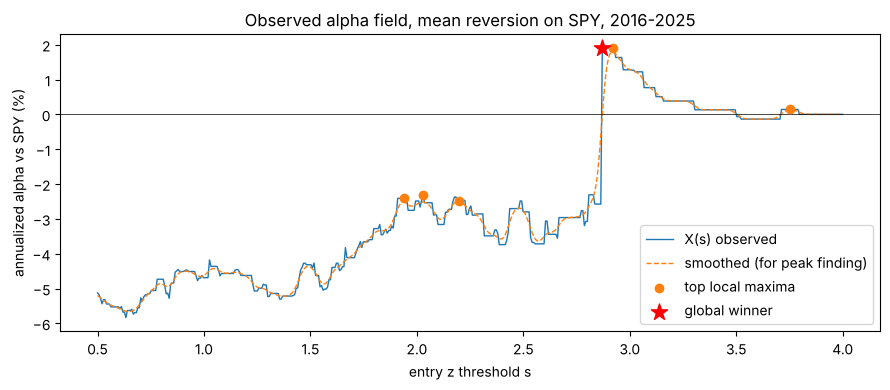

Saved real_field.csv (500, 3) and real_local_maxima.csv


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import argrelmax

LOOKBACK = 20            # rolling window for mean and SD
S_MIN, S_MAX, M = 0.5, 4.0, 500   # z-threshold domain D and grid size
SMOOTH_SIGMA = 3         # grid points; only used to find local maxima
TOP_K = 5
ANN = 252

P = pd.read_csv("spy_prices.csv", index_col=0, parse_dates=True)["close"]
r = P.pct_change().fillna(0.0).values            # daily SPY return
mu = P.rolling(LOOKBACK).mean().values
sd = P.rolling(LOOKBACK).std().values
z  = (P.values - mu) / sd                        # NaN for the first LOOKBACK-1 days
T = len(P)

s_grid = np.linspace(S_MIN, S_MAX, M)
pos = np.zeros((T, M))                 # pos[t, j] = position held DURING day t under threshold s_j
cur = np.zeros(M)                      # state decided at close of day t-1
n_entries = np.zeros(M)
for t in range(T):
    pos[t] = cur                       # position held today was decided yesterday
    if np.isnan(z[t]):
        continue
    enter = (cur == 0) & (z[t] < -s_grid)
    exit_ = (cur == 1) & (P.values[t] >= mu[t])
    n_entries += enter
    cur = np.where(enter, 1.0, np.where(exit_, 0.0, cur))

strat = pos * r[:, None]               # daily strategy return, cash earns 0

valid = ~np.isnan(z)                   # drop warm-up days so all s use the same sample
x = r[valid]; Y = strat[valid]
xc = x - x.mean()
beta = (xc[:, None] * (Y - Y.mean(0))).sum(0) / (xc ** 2).sum()
alpha_daily = Y.mean(0) - beta * x.mean()
X = alpha_daily * ANN

# ---- Winners ----
i_hat = int(np.argmax(X))
Xs = gaussian_filter1d(X, SMOOTH_SIGMA, mode="nearest")
loc = argrelmax(Xs)[0]
loc = loc[np.argsort(-X[loc])][:TOP_K]
print(f"Global winner: s_hat = {s_grid[i_hat]:.3f}, naive alpha = {X[i_hat]:.2%}, "
      f"beta = {beta[i_hat]:.2f}, entries = {int(n_entries[i_hat])}")
print(f"\nTop-{TOP_K} local maxima (of smoothed curve):")
tab = pd.DataFrame({"s": s_grid[loc], "naive_alpha": X[loc], "beta": beta[loc],
                    "n_entries": n_entries[loc].astype(int)}).round(4)
print(tab.to_string(index=False))
print(f"\nFraction of grid with zero trades: {(n_entries == 0).mean():.1%}")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(s_grid, X * 100, lw=1, label="X(s) observed")
ax.plot(s_grid, Xs * 100, lw=1, ls="--", label="smoothed (for peak finding)")
ax.scatter(s_grid[loc], X[loc] * 100, c="C1", zorder=3, label="top local maxima")
ax.scatter(s_grid[i_hat], X[i_hat] * 100, c="red", marker="*", s=150, zorder=4, label="global winner")
ax.axhline(0, c="k", lw=0.5)
ax.set_xlabel("entry z threshold s"); ax.set_ylabel("annualized alpha vs SPY (%)")
ax.set_title("Observed alpha field, mean reversion on SPY, 2016-2025"); ax.legend()
plt.tight_layout(); plt.show()

out = pd.DataFrame({"s": s_grid, "X_observed": X, "is_winner": np.arange(M) == i_hat})
out.to_csv("real_field.csv", index=False)
tab.to_csv("real_local_maxima.csv", index=False)
print("Saved real_field.csv", out.shape, "and real_local_maxima.csv")

Winner s_hat = 2.871
  naive alpha            = 1.91%   (bootstrap SE at s_hat = 1.16%)
  estimated winner's-curse bias = 1.56%
  bias-corrected alpha   = 0.35%
  global-max p-value (RC-style, unstudentized) = 0.592
  replicate argmax within 0.15 of s_hat: 74%


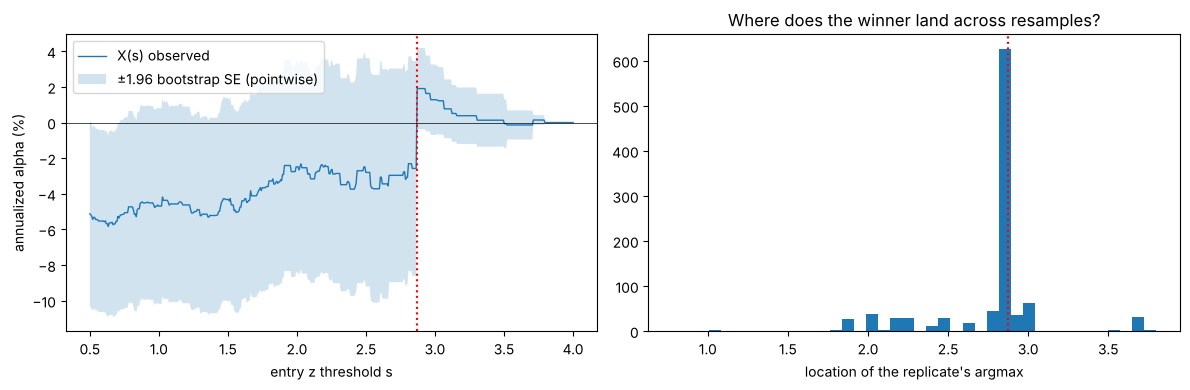

Saved real_field_boot.csv (500, 1001)


In [20]:
B = 1000                 # number of bootstrap replicates
MEAN_BLOCK = 20          # mean block length in days; check sensitivity at 10 and 40
SEED = 0
rng = np.random.default_rng(SEED)
Tn, Mn = Y.shape

def stationary_bootstrap_idx(T, mean_block, rng):
    """Politis-Romano: blocks start at a random day and have Geometric(1/mean_block) length (wraps around)."""
    new = rng.random(T) < 1.0 / mean_block
    new[0] = True
    block_id = np.cumsum(new) - 1
    starts = rng.integers(T, size=new.sum())
    first = np.flatnonzero(new)
    offset = np.arange(T) - first[block_id]
    return (starts[block_id] + offset) % T

def alpha_field(xb, Yb):
    xc = xb - xb.mean()
    beta = (xc[:, None] * (Yb - Yb.mean(0))).sum(0) / (xc ** 2).sum()
    return (Yb.mean(0) - beta * xb.mean()) * ANN

Xb = np.empty((Mn, B))
for b in range(B):
    idx = stationary_bootstrap_idx(Tn, MEAN_BLOCK, rng)
    Xb[:, b] = alpha_field(x[idx], Y[idx])

se = Xb.std(axis=1, ddof=1)                          # bootstrap SE of X(s) at each s

# Bias at the winner (Davenport-Nichols style): in each replicate, take the replicate's own peak
# and compare its value to the ORIGINAL field at that same location.
jb = Xb.argmax(axis=0)                               # replicate peak locations
peak_boot = Xb[jb, np.arange(B)]
bias = np.mean(peak_boot - X[jb])
X_corrected = X[i_hat] - bias

# Global-max p-value (Reality-Check style, centered at the observed field, H0: no s beats SPY)
max_null = (Xb - X[:, None]).max(axis=0)
p_global = (1 + np.sum(max_null >= X[i_hat])) / (B + 1)

near = np.mean(np.abs(s_grid[jb] - s_grid[i_hat]) < 0.15)
print(f"Winner s_hat = {s_grid[i_hat]:.3f}")
print(f"  naive alpha            = {X[i_hat]:.2%}   (bootstrap SE at s_hat = {se[i_hat]:.2%})")
print(f"  estimated winner's-curse bias = {bias:.2%}")
print(f"  bias-corrected alpha   = {X_corrected:.2%}")
print(f"  global-max p-value (RC-style, unstudentized) = {p_global:.3f}")
print(f"  replicate argmax within 0.15 of s_hat: {near:.0%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(s_grid, X * 100, lw=1, label="X(s) observed")
ax[0].fill_between(s_grid, (X - 1.96 * se) * 100, (X + 1.96 * se) * 100, alpha=0.2, label="±1.96 bootstrap SE (pointwise)")
ax[0].axhline(0, c="k", lw=0.5); ax[0].axvline(s_grid[i_hat], c="r", ls=":")
ax[0].set_xlabel("entry z threshold s"); ax[0].set_ylabel("annualized alpha (%)"); ax[0].legend()
ax[1].hist(s_grid[jb], bins=40)
ax[1].axvline(s_grid[i_hat], c="r", ls=":")
ax[1].set_xlabel("location of the replicate's argmax"); ax[1].set_title("Where does the winner land across resamples?")
plt.tight_layout(); plt.show()

cols = [f"b{k}" for k in range(B)]
rep = pd.DataFrame(Xb, columns=cols); rep.insert(0, "s", s_grid)
rep.to_csv("real_field_boot.csv", index=False, float_format="%.6g")
print("Saved real_field_boot.csv", rep.shape)

In [21]:
B_SENS = 500
rows = []
for L in [5, 10, 20, 40, 80]:
    rng_l = np.random.default_rng(SEED)
    Xl = np.empty((Mn, B_SENS))
    for b in range(B_SENS):
        idx = stationary_bootstrap_idx(Tn, L, rng_l)
        Xl[:, b] = alpha_field(x[idx], Y[idx])
    jl = Xl.argmax(axis=0)
    bias_l = np.mean(Xl[jl, np.arange(B_SENS)] - X[jl])
    p_l = (1 + np.sum((Xl - X[:, None]).max(axis=0) >= X[i_hat])) / (B_SENS + 1)
    rows.append({"mean_block": L,
                 "SE_at_winner": Xl[i_hat].std(ddof=1),
                 "bias": bias_l,
                 "corrected_alpha": X[i_hat] - bias_l,
                 "p_global": p_l,
                 "argmax_near_winner": np.mean(np.abs(s_grid[jl] - s_grid[i_hat]) < 0.15)})
sens = pd.DataFrame(rows)
print(sens.to_string(index=False, formatters={
    "SE_at_winner": "{:.2%}".format, "bias": "{:.2%}".format,
    "corrected_alpha": "{:.2%}".format, "p_global": "{:.3f}".format,
    "argmax_near_winner": "{:.0%}".format}))
sens.to_csv("block_length_sensitivity.csv", index=False)

 mean_block SE_at_winner  bias corrected_alpha p_global argmax_near_winner
          5        1.30% 1.30%           0.61%    0.619                72%
         10        1.21% 1.42%           0.48%    0.641                76%
         20        1.16% 1.63%           0.27%    0.593                73%
         40        1.08% 1.86%           0.04%    0.583                71%
         80        1.07% 1.93%          -0.02%    0.587                71%


### Notes from the original notebook

Alpha value of uncertainity

Assuming if thresholds are used in real time in trades, notion of prob guarentee if the alpha return for the top most threshold

presentation on what are finance that are relevant that firms care and what do they with thresholds

---
# Part IV: Exponential-mechanism winner and a conditional CI on SPY

## IV.1 Mapping the method to the backtest

* **Field.** $X(s)$ = full-sample annualized alpha vs SPY of the mean-reversion strategy with entry
  threshold $z<-s$ (Part III).
* **Estimand.** $\theta(s_J)$ = the *population* annualized alpha of the strategy at the threshold we
  select. It is what we'd expect to earn, net of SPY beta, if we deployed $s_J$ and the return process
  stayed stationary.
* **Covariance.** $\Sigma$ is unknown. We plug in $\hat\Sigma$ = covariance of the stationary-bootstrap
  replicates `Xb` from Part III. The bootstrap captures both the serial dependence of returns and the
  shared trade history of nearby thresholds. Only the column $\hat\Sigma_{\cdot J}$ and the diagonal are used.
* **Domain.** We declare $D$ to be the thresholds that actually trade enough for a Gaussian
  approximation to be sensible: at least `MIN_ENTRIES` entries over 10 years. (Thresholds with zero
  trades have $X\equiv0$ and zero variance; they carry no information.) This depends only on the
  price path's z-scores, not on the strategy P&L being ranked. The base measure is uniform on that set.

Validity here is **asymptotic**: it relies on $X\approx N(\theta,\hat\Sigma)$. IV.4 checks it inside the
bootstrap world, which doesn't assume Gaussianity.

Domain D: 358 of 500 grid points, s ∈ [0.500, 3.004]  (≥ 10 entries)
Naive argmax on D: s = 2.871, alpha = 1.91%


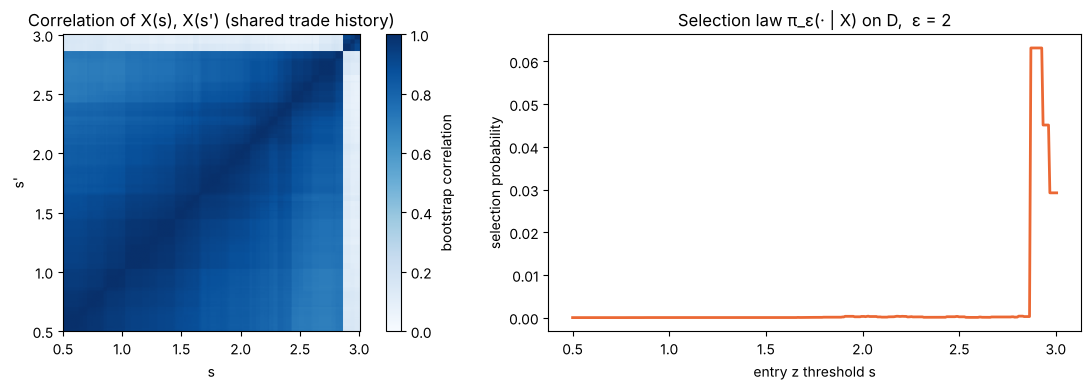

In [22]:
MIN_ENTRIES = 10
EPS_REAL = 2.0
SEL_SEED = 20260101          # fix (and ideally pre-register) the randomization seed before looking

dom = (n_entries >= MIN_ENTRIES) & (se > 0)
s_D, X_D = s_grid[dom], X[dom]
Xb_D = Xb[dom]
Sig_D = np.cov(Xb_D)                         # bootstrap covariance of the alpha field on D
sd_D = np.sqrt(np.diag(Sig_D))
corr_D = Sig_D / np.outer(sd_D, sd_D)
print(f"Domain D: {dom.sum()} of {M} grid points, s ∈ [{s_D.min():.3f}, {s_D.max():.3f}]  (≥ {MIN_ENTRIES} entries)")
print(f"Naive argmax on D: s = {s_D[np.argmax(X_D)]:.3f}, alpha = {X_D.max():.2%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
im = ax[0].imshow(corr_D, origin="lower", extent=[s_D[0], s_D[-1], s_D[0], s_D[-1]], cmap="Blues", vmin=0, vmax=1)
plt.colorbar(im, ax=ax[0], label="bootstrap correlation")
ax[0].set_xlabel("s"); ax[0].set_ylabel("s'"); ax[0].set_title("Correlation of X(s), X(s') (shared trade history)")
ax[1].plot(s_D, em_probs(X_D, EPS_REAL), c=C_ORANGE, lw=2)
ax[1].set_xlabel("entry z threshold s"); ax[1].set_ylabel("selection probability")
ax[1].set_title(f"Selection law π_ε(· | X) on D,  ε = {EPS_REAL:g}")
plt.tight_layout(); plt.show()

## IV.2 The reported result

One draw from the mechanism (fixed seed), then the conditional interval for the selected threshold's
true alpha.

                                       rule     s estimate  lower upper
                         argmax, naive Wald 2.871    1.91% -0.37% 4.19%
argmax, bootstrap bias-corrected (Part III) 2.871    0.35%    NaN   NaN
                       EM (ε=2), naive Wald 2.934    1.63% -0.49% 3.76%
               EM (ε=2), conditional (ours) 2.934    1.60% -0.56% 3.74%

Selected threshold s_J = 2.934: entries = 11, beta = 0.09, bootstrap SE = 1.08%
Interpretation: given that the randomized search selected s = 2.934, its true annualized alpha vs SPY lies in [-0.56%, 3.74%] with 95% conditional confidence; zero is inside the interval.


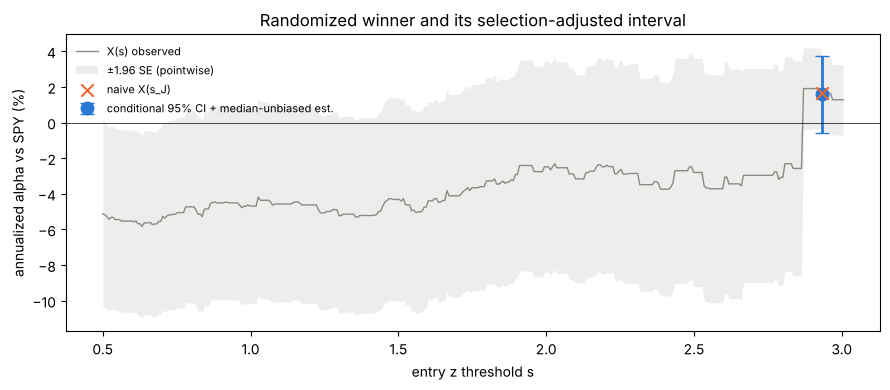

In [23]:
rng_sel = np.random.default_rng(SEL_SEED)
J = int(em_select(X_D, EPS_REAL, rng_sel))
res_real = conditional_inference(X_D, Sig_D[:, J], J, EPS_REAL, alpha=ALPHA)
i_arg = int(np.argmax(X_D))

report = pd.DataFrame([
    dict(rule="argmax, naive Wald", s=s_D[i_arg], estimate=X_D[i_arg],
         lower=X_D[i_arg] - 1.96 * sd_D[i_arg], upper=X_D[i_arg] + 1.96 * sd_D[i_arg]),
    dict(rule="argmax, bootstrap bias-corrected (Part III)", s=s_D[i_arg], estimate=X_corrected, lower=np.nan, upper=np.nan),
    dict(rule=f"EM (ε={EPS_REAL:g}), naive Wald", s=s_D[J], estimate=res_real["x"],
         lower=res_real["x"] - 1.96 * res_real["se"], upper=res_real["x"] + 1.96 * res_real["se"]),
    dict(rule=f"EM (ε={EPS_REAL:g}), conditional (ours)", s=s_D[J], estimate=res_real["mue"],
         lower=res_real["lower"], upper=res_real["upper"]),
])
print(report.to_string(index=False, formatters={"s": "{:.3f}".format, "estimate": "{:.2%}".format,
                                                 "lower": "{:.2%}".format, "upper": "{:.2%}".format}))
print(f"\nSelected threshold s_J = {s_D[J]:.3f}: entries = {int(n_entries[dom][J])}, beta = {beta[dom][J]:.2f}, "
      f"bootstrap SE = {res_real['se']:.2%}")
print(f"Interpretation: given that the randomized search selected s = {s_D[J]:.3f}, its true annualized alpha vs SPY "
      f"lies in [{res_real['lower']:.2%}, {res_real['upper']:.2%}] with {1 - ALPHA:.0%} conditional confidence;"
      f" zero is {'inside' if res_real['lower'] <= 0 <= res_real['upper'] else 'outside'} the interval.")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(s_D, X_D * 100, c=C_GRAY, lw=1, label="X(s) observed")
ax.fill_between(s_D, (X_D - 1.96 * sd_D) * 100, (X_D + 1.96 * sd_D) * 100, color=C_GRAY, alpha=0.15, lw=0, label="±1.96 SE (pointwise)")
ax.errorbar([s_D[J]], [res_real["mue"] * 100],
            yerr=[[(res_real["mue"] - res_real["lower"]) * 100], [(res_real["upper"] - res_real["mue"]) * 100]],
            fmt="o", ms=9, c=C_BLUE, lw=2, capsize=5, label="conditional 95% CI + median-unbiased est.")
ax.scatter([s_D[J]], [res_real["x"] * 100], marker="x", s=80, c=C_ORANGE, zorder=4, label="naive X(s_J)")
ax.axhline(0, c="k", lw=0.5)
ax.set_xlabel("entry z threshold s"); ax.set_ylabel("annualized alpha vs SPY (%)"); ax.legend(fontsize=8, frameon=False)
ax.set_title("Randomized winner and its selection-adjusted interval")
plt.tight_layout(); plt.show()

**Why is the correction small here?** The observed field jumps at $s\approx2.87$ to a short plateau that sits
far above every other threshold, and the thresholds on that plateau are almost perfectly correlated (they share
the same ~12 trades). So the mechanism lands on the plateau with near certainty whatever the noise on any one
threshold is, and conditioning on that choice costs little information. The bootstrap-world check in IV.4 shows
that *on average over datasets* the naive value is biased upward by about 1 percentage point, and the
conditional procedure removes it. In both cases the honest conclusion is the same as Part III's
Reality-Check p-value: no threshold shows alpha distinguishable from zero.

## IV.3 Sensitivity: other randomization draws and other ε

In practice we report **one** draw (with a seed fixed in advance). Each possible draw's interval is
conditionally valid, so it's worth seeing how much the reported threshold and interval move across
draws. Also, how $\epsilon$ trades off staying near the argmax against interval length.

    mean_s  sd_s mean_naive_X mean_MUE mean_length frac_lower_gt_0
eps                                                               
0.5  2.128 0.680       -2.33%   -2.77%       9.82%              0%
1.0  2.546 0.611       -0.31%   -1.11%       7.13%              0%
2.0  2.915 0.104        1.62%    1.42%       4.53%              0%
4.0  2.916 0.034        1.78%    1.71%       4.51%              0%
8.0  2.903 0.026        1.86%    1.77%       4.69%              0%


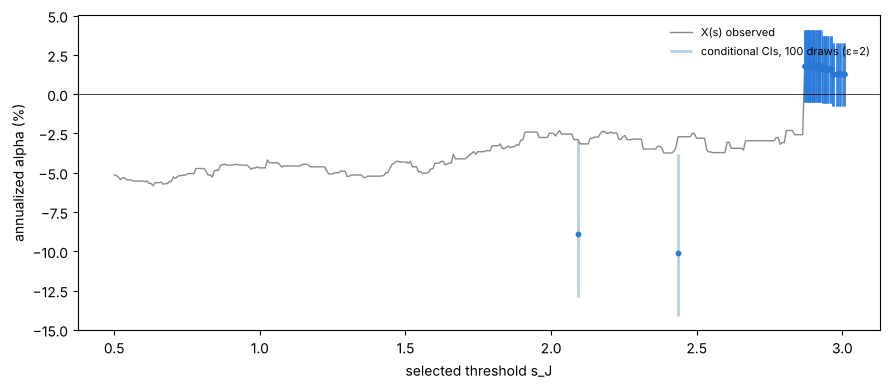

In [24]:
rows = []
for e in [0.5, 1.0, 2.0, 4.0, 8.0]:
    rg = np.random.default_rng(SEL_SEED)
    for k in range(100):
        j = int(em_select(X_D, e, rg))
        o = conditional_inference(X_D, Sig_D[:, j], j, e, alpha=ALPHA)
        rows.append(dict(eps=e, draw=k, s=s_D[j], X=o["x"], mue=o["mue"], lower=o["lower"], upper=o["upper"],
                         length=o["upper"] - o["lower"], excludes_0=o["lower"] > 0))
draws = pd.DataFrame(rows)
tab_e = draws.groupby("eps").agg(mean_s=("s", "mean"), sd_s=("s", "std"), mean_naive_X=("X", "mean"),
                                 mean_MUE=("mue", "mean"), mean_length=("length", "mean"),
                                 frac_lower_gt_0=("excludes_0", "mean"))
print(tab_e.to_string(formatters={"mean_s": "{:.3f}".format, "sd_s": "{:.3f}".format,
                                  "mean_naive_X": "{:.2%}".format, "mean_MUE": "{:.2%}".format,
                                  "mean_length": "{:.2%}".format, "frac_lower_gt_0": "{:.0%}".format}))

d2 = draws[draws.eps == EPS_REAL].sort_values("s").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(s_D, X_D * 100, c=C_GRAY, lw=1, label="X(s) observed")
ax.vlines(d2.s, d2.lower * 100, d2.upper * 100, color=C_BLUE, alpha=0.35, lw=2, label=f"conditional CIs, 100 draws (ε={EPS_REAL:g})")
ax.scatter(d2.s, d2.mue * 100, s=10, c=C_BLUE, zorder=3)
ax.axhline(0, c="k", lw=0.5)
ax.set_xlabel("selected threshold s_J"); ax.set_ylabel("annualized alpha (%)"); ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## IV.4 Calibration check in the bootstrap world

Coverage on real data can't be checked directly because $\theta(s)$ is unknown. Instead, as in Part III's bias
correction, treat the observed field as the truth ($\theta^\ast := X$) and each centred bootstrap
replicate $X^\ast_b = X + (X_b - \bar X_b)$ as a new dataset. Its noise has the real data's serial
dependence and non-Gaussian tails, and none of it is modelled. Run the full procedure (select with the
mechanism, invert the pivot with $\hat\Sigma$) on each $X^\ast_b$ and record whether the interval covers
$\theta^\ast(s_J)$.

Bootstrap-world check, 1000 replicates, ε = 2, nominal 95%:
  coverage  argmax + naive Wald     : 0.913   bias +1.18%
  coverage  EM + naive Wald         : 0.934   bias +1.10%
  coverage  EM + conditional (ours) : 0.951   bias +0.02% (median-unbiased est.)
  mean length: ours 7.39%  vs naive 6.49%


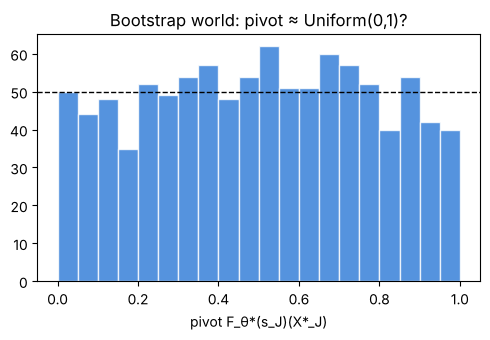

In [25]:
Xstar = X_D[:, None] + (Xb_D - Xb_D.mean(axis=1, keepdims=True))
rg = np.random.default_rng(1)
cal = []
for b in range(Xstar.shape[1]):
    xs = Xstar[:, b]
    j = int(em_select(xs, EPS_REAL, rg))
    o = conditional_inference(xs, Sig_D[:, j], j, EPS_REAL, alpha=ALPHA, theta0=X_D[j])
    i = int(np.argmax(xs))
    cal.append(dict(cov_ours=o["lower"] <= X_D[j] <= o["upper"], len_ours=o["upper"] - o["lower"], pivot=o["pivot"],
                    cov_naive_em=abs(xs[j] - X_D[j]) <= 1.96 * sd_D[j],
                    cov_naive_argmax=abs(xs[i] - X_D[i]) <= 1.96 * sd_D[i], len_naive=2 * 1.96 * sd_D[j],
                    err_ours=o["mue"] - X_D[j], err_naive_em=xs[j] - X_D[j], err_naive_argmax=xs[i] - X_D[i]))
cal = pd.DataFrame(cal)
print(f"Bootstrap-world check, {len(cal)} replicates, ε = {EPS_REAL:g}, nominal {1 - ALPHA:.0%}:")
print(f"  coverage  argmax + naive Wald     : {cal.cov_naive_argmax.mean():.3f}   bias {cal.err_naive_argmax.mean():+.2%}")
print(f"  coverage  EM + naive Wald         : {cal.cov_naive_em.mean():.3f}   bias {cal.err_naive_em.mean():+.2%}")
print(f"  coverage  EM + conditional (ours) : {cal.cov_ours.mean():.3f}   bias {cal.err_ours.mean():+.2%} (median-unbiased est.)")
print(f"  mean length: ours {cal.len_ours.mean():.2%}  vs naive {cal.len_naive.mean():.2%}")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(cal["pivot"], bins=20, range=(0, 1), color=C_BLUE, alpha=0.8, edgecolor="white")
ax.axhline(len(cal) / 20, c="k", ls="--", lw=1)
ax.set_xlabel("pivot F_θ*(s_J)(X*_J)"); ax.set_title("Bootstrap world: pivot ≈ Uniform(0,1)?")
plt.tight_layout(); plt.show()

## Summary and caveats

* **Selection rule.** The winner is drawn from the continuous Gibbs / exponential-mechanism kernel
  $\pi_\epsilon(\mathrm ds\mid X)\propto \exp\{\epsilon(X(s)-\bar X)/\hat\sigma_X\}\,\omega(\mathrm ds)$, discretized by quadrature.
  Results are stable as the grid is refined (II.6).
* **Inference.** Conditioning on the selected location and the residual field $R_J$ leaves a 1-D
  exponential-tilt family for $X_J$, whose pivot is exactly uniform under the Gaussian model (II.4).
  This gives conditional coverage at every selected location and a median-unbiased estimate that
  removes the winner's-curse bias.
* **Regret–length trade-off.** $\epsilon$ is the knob (II.5). When the signal is weak relative to the
  noise, as in Part I's world, no rule reliably finds the peak, and the honest interval is wide.
* **Real data.** Validity is asymptotic and uses a bootstrap $\hat\Sigma$. The domain $D$ and $\epsilon$ (and
  ideally the seed) should be fixed before looking at the P&L. The bootstrap-world check (IV.4)
  covers non-Gaussianity and serial dependence, but not non-stationarity of the market.
* **Not covered here.** Inference for the *global* best $\max_s\theta(s)$, for the location $s^\star$, or a
  near-optimal set $\{s:\theta(s)\ge\max\theta-\Delta\}$ (other rows of the targets table in the notes).
  These need different procedures.